In [1]:
pip install opencv-python numpy matplotlib

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: C:\Users\shash\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("All libraries imported successfully!")
print("OpenCV Version:", cv2.__version__)

All libraries imported successfully!
OpenCV Version: 5.0.0


Image loaded successfully!
Image dimensions: (1919, 1080)


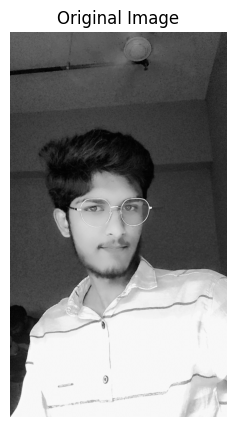

In [10]:
image = cv2.imread(r"c:\Users\shash\Documents\SHASHIDAHR_18\Photos\hello_26.jpg", cv2.IMREAD_GRAYSCALE)

if image is None:
    print("Image not found! Check the image path.")
else:
    print("Image loaded successfully!")
    print("Image dimensions:", image.shape)

    plt.figure(figsize=(6, 5))
    plt.imshow(image, cmap='gray')
    plt.title("Original Image")
    plt.axis('off')
    plt.show()

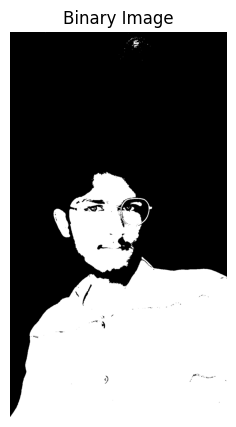

Binary image created successfully!
Unique pixel values: [0 1]


In [ ]:
# Converting grayscale image into binary image
_, binary = cv2.threshold(
    image, 127, 255, cv2.THRESH_BINARY
)

# Convert pixel values from 0/255 to 0/1
binary = (binary // 255).astype(np.uint8)
# Display binary image
plt.figure(figsize=(8, 5))
plt.imshow(binary, cmap='gray')
plt.title("Binary Image")
plt.axis('off')
plt.show()

print("Binary image created successfully!")
print("Unique pixel values:", np.unique(binary))

In [12]:
# Define structuring element

pattern = np.array([
    [-1,  1, -1],
    [ 1,  1,  1],
    [-1,  1, -1]
], dtype=np.int8)

print("Structuring Element:")
print(pattern)

Structuring Element:
[[-1  1 -1]
 [ 1  1  1]
 [-1  1 -1]]


In [13]:
# Invert binary image
binary_inv = 1 - binary

# Apply Hit or Miss Transformation
result = cv2.morphologyEx(
    binary_inv,
    cv2.MORPH_HITMISS,
    pattern
)

print("Hit or Miss Transformation applied successfully!")

Hit or Miss Transformation applied successfully!


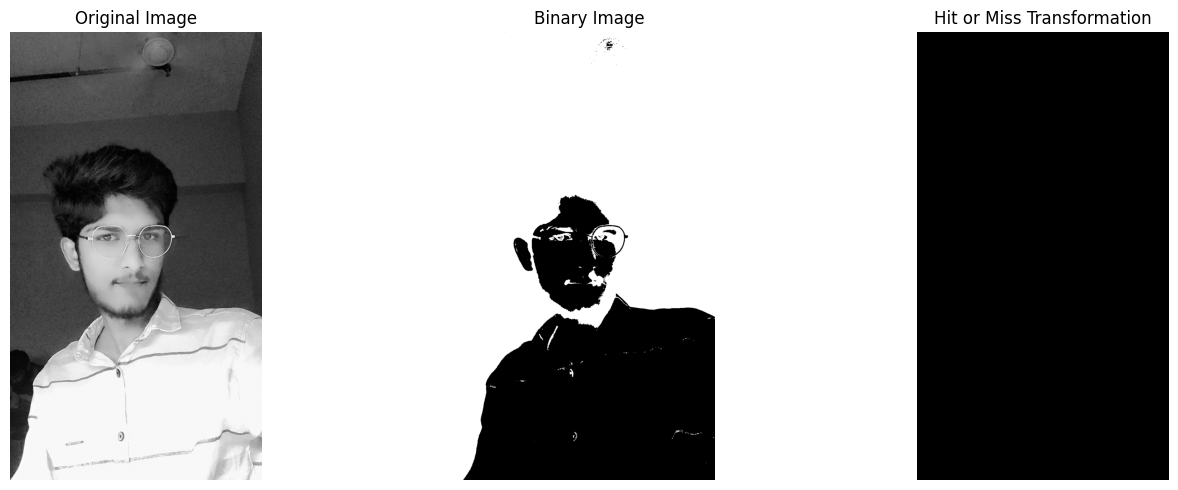

In [14]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image, cmap='gray')
plt.title("Original Image")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(binary_inv, cmap='gray')
plt.title("Binary Image")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(result, cmap='gray')
plt.title("Hit or Miss Transformation")
plt.axis('off')

plt.tight_layout()
plt.show()

In [17]:
detected_pixels = np.count_nonzero(result)
print("Number of detected pattern pixels:", detected_pixels)

Number of detected pattern pixels: 0


Detected Pixel Coordinates:
[]


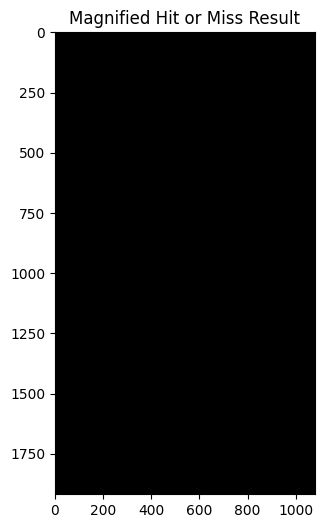

In [ ]:
# Find coordinates of detected pixels
coordinates = np.argwhere(result == 1)
print("Detected Pixel Coordinates:")
print(coordinates)
# Enlarge the result for better visualization
plt.figure(figsize=(8, 6))
plt.imshow(result, cmap='gray', interpolation='nearest')
plt.title("Magnified Hit or Miss Result")
plt.axis('on')
plt.show()